# Dataset #6: NBA.com Official Player Movement Log (July 2015 – present)

**Source and access.** NBA.com's transactions page is built from a single public JSON file, `https://stats.nba.com/js/data/playermovement/NBA_Player_Movement.json`. It needs no account or API key, and `00-Download-Raw-Data.ipynb` downloads it in one request into `data-files/00-raw/nba_player_movement.json`. This is the league's own record of transactions, so it is more authoritative than fan-maintained sites. 

**Structure and important variables.** The file has one row per *transaction line*, about 10,000 rows from 2015-07-01 onward. Each row has:
- `Transaction_Type`: one of `Trade`, `Signing`, `Waive`, `ContractConverted` (e.g. two-way to standard), or `AwardOnWaivers` (claimed off waivers). Trades are what we want to predict. The other types help explain *why* a player changed teams (for example, a player who changed teams without being traded left in free agency).
- `TRANSACTION_DATE`: the date the transaction became official (a day, with no time). We use it to decide whether a trade happened during the **offseason** or the **season**. Trading is frozen from the trade deadline (February, or March in 2021) until the season ends, so there are no trades in April or May. We define the offseason after season *S*-(*S*+1) as **April 1 of year *S*+1 up to the day before opening night of the next season**. This also handles the 2020 bubble year, when the offseason ran from October to December 22, 2020.
- `TRANSACTION_DESCRIPTION`: free text such as *"Washington Wizards received guard Tyus Jones from Memphis Grizzlies."* For trades we extract the **receiving team**, the **sending team**, the player's **position** (guard / forward / center), and the **player name**. Picks and cash appear only as *"received draft consideration,"* with no detail about which pick.
- `TEAM_ID` / `TEAM_SLUG`: the receiving team (NBA.com's 10-digit team ID and a short name like `thunder`). `Additional_Sort`: for trades, the NBA team ID of the **sending** team; for other types it is 0.
- `PLAYER_ID` / `PLAYER_SLUG`: NBA.com's player ID and URL slug. `PLAYER_ID` is 0 for "draft consideration" rows.
- `GroupSort`: the transaction type plus an ID, e.g. `Trade 2022130`. All rows of one trade share this ID, so it tells us which players moved in the same deal. A trade has 1–16 rows (one per asset received by one team).

Each traded player becomes one row in `offseason_traded_players` (offseason year, player, from team, to team). That gives us the outcome label for the player-season table from Dataset #5: was this player traded in the offseason that followed this season?

**Concerns.**
1. *Coverage starts July 1, 2015.* Trades made during the 2015 draft (June 25, 2015) are missing, so the offseason after 2014-15 is incomplete. This doesn't affect us, because our salary data (Dataset #5) starts with 2015-16, whose offseason is summer 2016.
2. *Picks and cash have no detail.* Every pick or cash payment is recorded as "draft consideration" with `PLAYER_ID = 0`. We can tell a trade included picks, but not how many or how valuable they were.
3. *Missing values are coded as 0.* There are no NaN cells, but `PLAYER_ID = 0` and `Additional_Sort = 0` mean "not applicable." If we treated those zeros as real IDs, joins and counts would be wrong, so we convert them to NaN.
4. *Small inconsistencies.* The claimed-off-waivers type is spelled `AwardOnWaivers` in `Transaction_Type` but `AwardedOnWaivers` in `GroupSort`. The Clippers are "LA Clippers" here and "Los Angeles Clippers" in Dataset #5. Ten signings were recorded twice under different IDs.
5. *Name-based linking.* NBA.com player IDs differ from the HoopsHype IDs in Dataset #5, so we link the two on a normalized player name. Players with different names in the two sources (e.g. legal name vs. nickname) won't match, and newly drafted players traded on draft night have no earlier NBA salary to match to.
6. *Re-routed trades.* Some players are traded twice within days (e.g. Buddy Hield in September 2026, Atlanta → Charlotte → Chicago), where one team acts as a short stop in a larger deal. They count once in our offseason label, but for the second trade their "from" team is not the team they actually played for, so we use their *first* offseason trade.
7. *Live file.* The file is updated as new transactions happen, so re-downloading it later adds rows. We record the date range we loaded so the results can be reproduced.

## Setup

All file paths come from `nba_cleaning_utils.py`, which points at the `data-files/` folder (`RAW` = `00-raw/`, `INTERIM` = `01-interim/`, `PROCESSED` = `02-processed/`).

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Same name key as Dataset #5, so offseason trades can be joined to player-season salaries
from nba_cleaning_utils import RAW, INTERIM, PROCESSED, normalize_name

## 6A. Load the dataset

In [2]:
## 6A. LOAD the dataset (raw JSON downloaded into data-files/00-raw/ by 00-Download-Raw-Data)
with open(RAW / 'nba_player_movement.json', encoding='utf-8') as f:
    pm_json = json.load(f)

# The JSON stores a column schema plus a list of row dicts
print('Columns (from the file schema):',
      [(c['Name'], c['DataType']) for c in pm_json['NBA_Player_Movement']['columns']])
movement_raw = pd.DataFrame(pm_json['NBA_Player_Movement']['rows'])
display(movement_raw.head())

Columns (from the file schema): [('Transaction_Type', 'String'), ('TRANSACTION_DATE', 'DateTime'), ('TRANSACTION_DESCRIPTION', 'String'), ('TEAM_ID', 'Decimal'), ('TEAM_SLUG', 'String'), ('PLAYER_ID', 'Decimal'), ('PLAYER_SLUG', 'String'), ('Additional_Sort', 'Decimal'), ('GroupSort', 'String')]


,Transaction_Type,TRANSACTION_DATE,TRANSACTION_DESCRIPTION,TEAM_ID,TEAM_SLUG,PLAYER_ID,PLAYER_SLUG,Additional_Sort,GroupSort
0,Trade,2026-11-08T00:00:00,Oklahoma City Thunder received guard Nique Cli...,1.610613e+09,thunder,1642363.0,nique-clifford,1.610613e+09,Trade 2026018
1,Waive,2026-11-08T00:00:00,Oklahoma City Thunder waived forward Dalen Terry.,1.610613e+09,thunder,1631207.0,dalen-terry,0.000000e+00,Waive 1157634
2,Signing,2026-11-07T00:00:00,Memphis Grizzlies signed guard Richie Saunders...,1.610613e+09,grizzlies,1643563.0,richie-saunders,0.000000e+00,Signing 1157609
3,Signing,2026-11-07T00:00:00,Cleveland Cavaliers signed forward Riley Minix...,1.610613e+09,cavaliers,1642434.0,riley-minix,0.000000e+00,Signing 1157611
4,Waive,2026-11-07T00:00:00,Memphis Grizzlies waived forward Carson Cooper.,1.610613e+09,grizzlies,1643721.0,carson-cooper,0.000000e+00,Waive 1157626


## 6B. Tidy the dataset (or show it is already tidy)

In [3]:
## 6B. TIDY the dataset
# The raw table is *almost* tidy (one row per transaction line), but three columns pack several variables
# into one string, so we split them:
#   - GroupSort "Trade 2022130"  -> transaction type + transaction_id (the id that groups one trade's rows)
#   - TRANSACTION_DESCRIPTION    -> for trades: to_team, asset (position + player, or "draft consideration"),
#                                   from_team
#   - TRANSACTION_DATE (text)    -> a real datetime
# After this, each row is one observation (one asset received by one team in one transaction) and each
# column is one variable.
movement = movement_raw.rename(columns={
    'Transaction_Type': 'transaction_type', 'TRANSACTION_DESCRIPTION': 'description',
    'TEAM_ID': 'team_id', 'TEAM_SLUG': 'team_slug', 'PLAYER_ID': 'player_id',
    'PLAYER_SLUG': 'player_slug', 'Additional_Sort': 'from_team_id'})
movement['date'] = pd.to_datetime(movement['TRANSACTION_DATE'])
movement['transaction_id'] = movement['GroupSort'].str.split(' ').str[-1]

TRADE_PATTERN = (r'^(?P<to_team>.+?) received '
                 r'(?:(?P<position>guard|forward|center) (?P<player>.+?)|(?P<other_asset>draft consideration))'
                 r' from (?P<from_team>.+?)\.?$')
is_trade = movement['transaction_type'].eq('Trade')
parsed = movement.loc[is_trade, 'description'].str.extract(TRADE_PATTERN)
movement = movement.join(parsed)

print('Trade rows whose description did NOT fit the pattern:',
      parsed['to_team'].isna().sum(), 'of', is_trade.sum())
movement = movement.drop(columns=['TRANSACTION_DATE', 'GroupSort'])
display(movement[is_trade].head())

Trade rows whose description did NOT fit the pattern: 0 of 1813


,transaction_type,description,team_id,team_slug,player_id,player_slug,from_team_id,date,transaction_id,to_team,position,player,other_asset,from_team
0,Trade,Oklahoma City Thunder received guard Nique Cli...,1.610613e+09,thunder,1642363.0,nique-clifford,1.610613e+09,2026-11-08,2026018,Oklahoma City Thunder,guard,Nique Clifford,NaN,Sacramento Kings
228,Trade,Chicago Bulls received guard Buddy Hield from ...,1.610613e+09,bulls,1627741.0,buddy-hield,1.610613e+09,2026-09-27,2026017,Chicago Bulls,guard,Buddy Hield,NaN,Charlotte Hornets
229,Trade,Charlotte Hornets received guard Rob Dillingha...,1.610613e+09,hornets,1642265.0,rob-dillingham,1.610613e+09,2026-09-27,2026017,Charlotte Hornets,guard,Rob Dillingham,NaN,Chicago Bulls
283,Trade,Atlanta Hawks received forward Dorian Finney-S...,1.610613e+09,hawks,1627827.0,dorian-finney-smith,1.610613e+09,2026-09-22,2026016,Atlanta Hawks,forward,Dorian Finney-Smith,NaN,Charlotte Hornets
284,Trade,Charlotte Hornets received guard Ryan Nembhard...,1.610613e+09,hornets,1642948.0,ryan-nembhard,1.610613e+09,2026-09-22,2026016,Charlotte Hornets,guard,Ryan Nembhard,NaN,Atlanta Hawks


## 6C. Size of the dataset

All transaction rows: (10139, 14)
Date range: 2015-07-01 to 2026-11-08
Trade rows: 1813 | distinct trades: 504 | distinct traded players: 662


transaction_type,Signing,Waive,Trade,ContractConverted,AwardOnWaivers
rows,4667,3447,1813,139,73


date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
transaction_type,,,,,,,,,,,,
AwardOnWaivers,3,6,8,5,15,6,8,4,5,4,5,4
ContractConverted,0,0,5,13,18,6,12,23,17,17,13,15
Signing,252,391,370,367,382,321,529,428,412,418,410,387
Trade,56,93,131,131,173,158,187,165,192,165,174,188
Waive,187,236,245,285,279,198,290,328,320,326,378,375


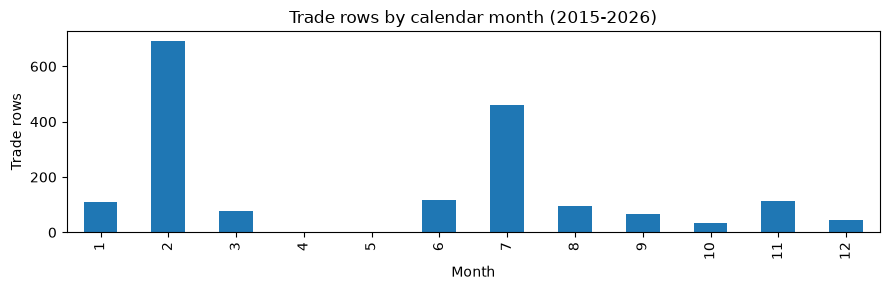

In [4]:
## 6C. SIZE of the dataset
trades_only = movement[movement['transaction_type'].eq('Trade')]
print('All transaction rows:', movement.shape)
print(f"Date range: {movement['date'].min().date()} to {movement['date'].max().date()}")
print('Trade rows:', len(trades_only), '| distinct trades:', trades_only['transaction_id'].nunique(),
      '| distinct traded players:', trades_only['player_id'].replace(0, np.nan).nunique())
display(movement['transaction_type'].value_counts().rename('rows').to_frame().T)

# Rows by calendar year and type (2015 starts in July; the current year is still in progress)
display(pd.crosstab(movement['date'].dt.year, movement['transaction_type']).T)

# When do trades happen? No trades in April-May (trading is frozen after the deadline until the season
# ends), which is what lets us separate offseason trades from in-season trades.
fig, ax = plt.subplots(figsize=(9, 3))
trades_only['date'].dt.month.value_counts().reindex(range(1, 13), fill_value=0).plot.bar(ax=ax)
ax.set_title('Trade rows by calendar month (2015-2026)')
ax.set_xlabel('Month'); ax.set_ylabel('Trade rows')
plt.tight_layout(); plt.show()

## 6D. Missing data: how much, where, and is it random?

In [5]:
## 6D. MISSINGNESS -- how much, where, and is it random?
# 1) Explicit NaNs in the raw file: none
display(movement_raw.isna().sum().rename('n_NaN').to_frame().T)

# 2) Missing values hidden as 0 (sentinel values)
sentinel = pd.DataFrame({
    'player_id == 0':    movement['player_id'].eq(0),
    'from_team_id == 0': movement['from_team_id'].eq(0)})
display(sentinel.groupby(movement['transaction_type']).sum())
# -> player_id is 0 only for trade rows that move "draft consideration" (picks/cash), and from_team_id is
#    0 for every non-trade row. Both are STRUCTURAL ("not applicable"), not random. We convert them to NaN
#    in 6F so they don't get treated as real ids.
print('Trade rows with player_id 0 that are NOT draft consideration:',
      (movement['player_id'].eq(0) & is_trade & movement['other_asset'].isna()).sum())

# 3) Missing by design in the parsed trade columns: position/player are empty exactly when the asset is
#    draft consideration, and the other way around.
display(movement.loc[is_trade, ['position', 'player', 'other_asset']].isna().sum().rename('n_missing').to_frame().T)

# 4) Missing coverage (whole periods absent): the file begins 2015-07-01, so 2015 draft-night trades
#    (June 25, 2015) are missing. Rows per year are much lower in 2015 because only half the year is covered.
print('First trade in the file:', trades_only['date'].min().date())

,Transaction_Type,TRANSACTION_DATE,TRANSACTION_DESCRIPTION,TEAM_ID,TEAM_SLUG,PLAYER_ID,PLAYER_SLUG,Additional_Sort,GroupSort
n_NaN,0,0,0,0,0,0,0,0,0


,player_id == 0,from_team_id == 0
transaction_type,,
AwardOnWaivers,0,73
ContractConverted,0,139
Signing,0,4667
Trade,520,0
Waive,0,3447


Trade rows with player_id 0 that are NOT draft consideration: 0


,position,player,other_asset
n_missing,520,520,1293


First trade in the file: 2015-07-09


## 6E. Outliers and suspicious entries

In [6]:
## 6E. OUTLIERS / SUSPICIOUS ENTRIES
trades_only = movement[is_trade]

# Trade size: rows (assets received) per trade, flagged with the IQR rule
rows_per_trade = trades_only.groupby('transaction_id').size()
q1, q3 = rows_per_trade.quantile([.25, .75])
big_cut = q3 + 1.5 * (q3 - q1)
print(f'Rows per trade: median {rows_per_trade.median():.0f}, max {rows_per_trade.max()}; '
      f'IQR outlier cut-off > {big_cut:.1f} -> {(rows_per_trade > big_cut).sum()} large trades flagged')
biggest = rows_per_trade.idxmax()
display(trades_only[trades_only['transaction_id'] == biggest][['date', 'description']])

suspicious = pd.DataFrame({
    # exact same date + description + player recorded twice under different ids
    'duplicate_entry': movement.duplicated(['date', 'description', 'player_id'], keep=False),
    # a team trading with itself would be impossible
    'trade_with_self': is_trade & movement['to_team'].eq(movement['from_team']),
    'trade_in_apr_may': is_trade & movement['date'].dt.month.isin([4, 5]),   # trading is frozen then
    # parsed player name should agree with NBA.com's own slug
    'name_slug_mismatch': is_trade & movement['player'].notna()
                          & (movement['player'].str.lower().str.replace(r'[^a-z0-9 -]', '', regex=True)
                             .str.replace(' ', '-') != movement['player_slug']),
    'future_date': movement['date'] > pd.Timestamp.today().normalize(),
})
display(suspicious.sum().rename('n_flagged').to_frame().T)
display(movement[suspicious['duplicate_entry']].sort_values(['date', 'description'])
        [['date', 'transaction_type', 'description', 'transaction_id']].head(6))

# Each team name in the text should always map to the same team id (and vice versa)
print('Receiving-team names per TEAM_ID (should all be 1):',
      trades_only.groupby('team_id')['to_team'].nunique().max())
print('Sending-team names per from_team_id (should all be 1):',
      trades_only.groupby('from_team_id')['from_team'].nunique().max())

# Players traded more than once within a few weeks (re-routed through a third team)
player_trades = trades_only.dropna(subset=['player']).sort_values('date')
gap = player_trades.groupby('player_id')['date'].diff().dt.days
quick = player_trades[gap.le(14) | gap.shift(-1).le(14)]
print('Trade rows where the same player is traded again within 14 days:', len(quick))
display(quick[['date', 'description']].head(6))

# Label typo: two spellings for the same transaction type
print('Type spellings:', sorted(movement['transaction_type'].unique()),
      '| GroupSort prefixes:', sorted(movement_raw['GroupSort'].str.split(' ').str[0].unique()))

Rows per trade: median 3, max 16; IQR outlier cut-off > 7.6 -> 35 large trades flagged


,date,description
502,2026-07-08,Dallas Mavericks received forward Santi Aldama...
503,2026-07-08,Dallas Mavericks received guard Marcus Sasser ...
504,2026-07-08,LA Clippers received draft consideration from ...
505,2026-07-08,Milwaukee Bucks received guard Caris LeVert fr...
506,2026-07-08,Milwaukee Bucks received draft consideration f...
507,2026-07-08,Memphis Grizzlies received guard AJ Johnson fr...
508,2026-07-08,Memphis Grizzlies received draft consideration...
509,2026-07-08,Memphis Grizzlies received guard D'Angelo Russ...
510,2026-07-08,Memphis Grizzlies received draft consideration...
511,2026-07-08,Memphis Grizzlies received forward Isaiah Stew...


,duplicate_entry,trade_with_self,trade_in_apr_may,name_slug_mismatch,future_date
n_flagged,20,0,0,0,0


,date,transaction_type,description,transaction_id
9382,2016-07-07,Signing,Los Angeles Lakers re-signed center Ivica Zuba...,976227
9403,2016-07-07,Signing,Los Angeles Lakers re-signed center Ivica Zuba...,976266
6864,2019-07-11,Signing,Golden State Warriors signed guard Alec Burks ...,1019112
6868,2019-07-11,Signing,Golden State Warriors signed guard Alec Burks ...,1019119
6064,2020-11-27,Signing,Chicago Bulls signed forward Noah Vonleh to a ...,1033468
6067,2020-11-27,Signing,Chicago Bulls signed forward Noah Vonleh to a ...,1033476


Receiving-team names per TEAM_ID (should all be 1): 1
Sending-team names per from_team_id (should all be 1): 1
Trade rows where the same player is traded again within 14 days: 125


,date,description
9928,2015-07-27,Golden State Warriors received forward Gerald ...
9897,2015-07-31,Philadelphia 76ers received forward Gerald Wal...
9579,2016-02-18,Utah Jazz received guard Shelvin Mack from Atl...
9580,2016-02-18,Portland Trail Blazers received guard Brian Ro...
8902,2017-01-07,Atlanta Hawks received guard Mike Dunleavy fro...
8893,2017-01-18,Denver Nuggets received guard Mo Williams from...


Type spellings: ['AwardOnWaivers', 'ContractConverted', 'Signing', 'Trade', 'Waive'] | GroupSort prefixes: ['AwardedOnWaivers', 'ContractConverted', 'Signing', 'Trade', 'Waive']


## 6F. Clean the data (and justify missing-data handling)

In [7]:
## 6F. CLEAN + build the offseason-trade table
# Cleaning decisions (and why):
#  1. Sentinel zeros -> NaN (player_id 0 and from_team_id 0 mean "not applicable"). We do NOT drop these
#     rows: draft-consideration rows are real parts of trades (they tell us a trade included picks/cash).
#  2. Drop the 10 duplicated signing rows (same date, description and player under two ids): keep the first.
#  3. Harmonize the waiver-claim label ("AwardOnWaivers" vs "AwardedOnWaivers" -> "AwardedOnWaivers").
#  4. Map NBA.com team names to the names used in Dataset #5 ("LA Clippers" -> "Los Angeles Clippers").
#  5. Assign each transaction to an NBA season and phase (offseason vs in-season) using opening-night
#     dates. Offseason after season S = April 1 of S+1 up to the day before the next opening night.
#  6. Large trades and quickly re-routed players are kept (they are real), but stay flagged.
movement_clean = (movement
                  .drop_duplicates(['date', 'description', 'player_id'], keep='first')
                  .assign(player_id=lambda d: d['player_id'].replace(0, np.nan),
                          from_team_id=lambda d: d['from_team_id'].replace(0, np.nan),
                          transaction_type=lambda d: d['transaction_type']
                                                      .replace('AwardOnWaivers', 'AwardedOnWaivers'))
                  .reset_index(drop=True))
for col in ['to_team', 'from_team']:
    movement_clean[col] = movement_clean[col].replace('LA Clippers', 'Los Angeles Clippers')

# Opening night of each season (season_year = first calendar year of the season, as in Dataset #5).
# Source: NBA schedules; 2020-21 opened late (Dec 22, 2020) after the COVID bubble.
OPENING_NIGHT = pd.to_datetime(pd.Series({
    2015: '2015-10-27', 2016: '2016-10-25', 2017: '2017-10-17', 2018: '2018-10-16', 2019: '2019-10-22',
    2020: '2020-12-22', 2021: '2021-10-19', 2022: '2022-10-18', 2023: '2023-10-24', 2024: '2024-10-22',
    2025: '2025-10-21', 2026: '2026-10-20'}))


def season_and_phase(date):
    """Return (season_year whose games come before this date or contain it, phase)."""
    started = OPENING_NIGHT[OPENING_NIGHT <= date]
    season = started.index.max() if len(started) else 2014          # before Oct 2015 -> 2014-15 season
    if date >= pd.Timestamp(year=season + 1, month=4, day=1):
        return season, 'offseason'      # after this season's trading freeze, before the next opener
    return season, 'in_season'


movement_clean[['season_year', 'phase']] = movement_clean['date'].apply(
    lambda d: pd.Series(season_and_phase(d)))
movement_clean['season_year'] = movement_clean['season_year'].astype(int)
# The offseason after season S belongs to S: e.g. a trade on 2025-07-06 is in the offseason after 2024-25.
movement_clean.loc[movement_clean['phase'].eq('offseason'), 'offseason_after_season'] = \
    movement_clean['season_year']

trades_clean = movement_clean[movement_clean['transaction_type'].eq('Trade')].copy()
trades_clean['large_trade_flag'] = trades_clean['transaction_id'].map(rows_per_trade > big_cut)
display(pd.crosstab(trades_clean['season_year'], trades_clean['phase']))

# One row per player traded in a given offseason. If a player was traded more than once in the same
# offseason (re-routed), keep the first trade, whose from_team is the team the player actually played for.
offseason_traded_players = (trades_clean[trades_clean['phase'].eq('offseason') & trades_clean['player'].notna()]
                            .sort_values('date')
                            .assign(name_key=lambda d: d['player'].map(normalize_name),
                                    n_offseason_trades=lambda d: d.groupby(['offseason_after_season', 'player_id'])
                                                                  ['transaction_id'].transform('nunique'))
                            .drop_duplicates(['offseason_after_season', 'player_id'], keep='first')
                            [['offseason_after_season', 'date', 'transaction_id', 'player_id', 'player',
                              'name_key', 'position', 'from_team', 'to_team', 'n_offseason_trades']]
                            .astype({'offseason_after_season': int, 'player_id': int})
                            .reset_index(drop=True))

print('Rows removed (duplicates):', len(movement) - len(movement_clean))
print('Remaining NaNs are structural (not-applicable fields):')
display(trades_clean[['player_id', 'player', 'position', 'other_asset', 'from_team_id']].isna().sum().to_frame('n_NaN').T)
display(offseason_traded_players.groupby('offseason_after_season').size().rename('players traded').to_frame().T)
offseason_traded_players.head()

phase,in_season,offseason
season_year,,
2014,0,50
2015,49,47
2016,57,70
2017,63,55
2018,107,83
2019,70,91
2020,101,86
2021,96,69
2022,87,88


Rows removed (duplicates): 10
Remaining NaNs are structural (not-applicable fields):


,player_id,player,position,other_asset,from_team_id
n_NaN,520,520,520,1293,0


offseason_after_season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
players traded,30,34,50,38,56,55,55,48,47,42,43,57


,offseason_after_season,date,transaction_id,player_id,player,name_key,position,from_team,to_team,n_offseason_trades
0,2014,2015-07-09,2015008,2585,Zaza Pachulia,zaza pachulia,center,Milwaukee Bucks,Dallas Mavericks,1
1,2014,2015-07-09,2015001,201168,Tiago Splitter,tiago splitter,center,San Antonio Spurs,Atlanta Hawks,1
2,2014,2015-07-09,2015002,203493,Reggie Bullock Jr.,reggie bullock,guard,Phoenix Suns,Detroit Pistons,1
3,2014,2015-07-09,2015002,202694,Marcus Morris Sr.,marcus morris,forward,Phoenix Suns,Detroit Pistons,1
4,2014,2015-07-09,2015002,101122,Danny Granger,danny granger,forward,Phoenix Suns,Detroit Pistons,1


## 6G. Save: raw (`data-files/00-raw`) → interim (`data-files/01-interim`) → processed (`data-files/02-processed`)

In [8]:
## 6G. SAVE: raw -> interim -> processed
# The raw JSON in data-files/00-raw/ is never modified.
# Intermediate: every transaction (all types), parsed and cleaned, with season/phase labels
movement_clean.to_csv(INTERIM / 'nba_transactions_parsed.csv', index=False)
# Final, fully wrangled tables
trades_clean.to_csv(PROCESSED / 'nba_trades.csv', index=False)
offseason_traded_players.to_csv(PROCESSED / 'offseason_traded_players.csv', index=False)

for path in [INTERIM / 'nba_transactions_parsed.csv',
             PROCESSED / 'nba_trades.csv',
             PROCESSED / 'offseason_traded_players.csv']:
    print(f'{path}: {os.path.getsize(path) / 1024:.0f} KB')

..\data-files\01-interim\nba_transactions_parsed.csv: 1662 KB
..\data-files\02-processed\nba_trades.csv: 402 KB
..\data-files\02-processed\offseason_traded_players.csv: 56 KB
